#**TUTORIAS SABADO 24**

In [5]:
class Cohete:
    def __init__(self, nombre):
        self.nombre = nombre

    def crear_mensaje(self, prefijo):
        def mensaje(numero):
            return f"{prefijo} {self.nombre}: {numero}"
        return mensaje

    def cuenta_regresiva(self, n, mensaje):
        # Recursividad
        if n == 0:
            print(f"¡Despegue de {self.nombre}! ")
            return
        print(mensaje(n))
        self.cuenta_regresiva(n - 1, mensaje)


cohete = Cohete("Apolo")
mi_mensaje = cohete.crear_mensaje("Faltan")
cohete.cuenta_regresiva(3, mi_mensaje)

Faltan Apolo: 3
Faltan Apolo: 2
Faltan Apolo: 1
¡Despegue de Apolo! 


##**Desarrollados en Casa**

In [ ]:
# Secuencia Fibonacci
def fibonacci(n):
    suma = 0
    if n == 0:
        return 0
    elif n == 1:
        return 1
    else:
        suma = fibonacci(n-2) + fibonacci (n-1)
    return suma

print("--- Secuencia Fibonacci ---")
# prueba para el numero 10
fibo = fibonacci(10)
print(fibo)


In [4]:
# Emiliana

# Torres de Hanoi
def hanoi(n, origen, destino, auxiliar):
    # caso base, movemos el disco del origen al destino
    if n == 1:
        print(f"Mover disco 1 de {origen} a {destino}")
        return

    # movemos los n-1 discos de arriba desde el origen hacia el auxiliar
    hanoi(n - 1, origen, auxiliar, destino)

    # movemos el disco grande al destino
    print(f"Mover disco {n} de {origen} a {destino}")

    # movemos los n-1 discos que dejamos en el auxiliar hacia el destino
    hanoi(n - 1, auxiliar, destino, origen)

print("--- Torres de Hanoi ---")
#prueba de la funcion con 3 discos
hanoi(3, "A", "C", "B")

--- Torres de Hanoi ---
Mover disco 1 de A a C
Mover disco 2 de A a B
Mover disco 1 de C a B
Mover disco 3 de A a C
Mover disco 1 de B a A
Mover disco 2 de B a C
Mover disco 1 de A a C


**Ejercicio Extra**

Simular el pago de un carrito de compras en una tienda en línea

In [ ]:
# Función que devuelve función (un cupón de descuento)
def crear_cupon(porcentaje):
    def aplicar(precio):
        return precio * (1 - porcentaje / 100)
    return aplicar


class Producto:
    def __init__(self, nombre, precio):
        self.nombre = nombre
        self.precio = precio


# Recursividad: suma los productos de uno en uno
def total_carrito(productos, cupon):
    if len(productos) == 0:  # caso base: carrito vacío
        return 0
    primero = productos[0]
    resto = productos[1:]
    return cupon(primero.precio) + total_carrito(resto, cupon)


# Clase padre
class MetodoPago:
    def __init__(self, titular):
        self.titular = titular

    def descripcion(self):
        return "método de pago"

    def comision(self, monto):
        return 0

    def pagar(self, monto):
        total = monto + self.comision(monto)
        return f"{self.titular} pagó ${total:.2f} con {self.descripcion()}"


# Clases hijas
class TarjetaCredito(MetodoPago):
    def __init__(self, titular, ultimos4):
        super().__init__(titular)
        self.ultimos4 = ultimos4

    def descripcion(self):
        return f"Tarjeta terminada en {self.ultimos4}"

    def comision(self, monto):
        return monto * 0.03  # 3%


class PayPal(MetodoPago):
    def __init__(self, titular, email):
        super().__init__(titular)
        self.email = email

    def descripcion(self):
        return f"PayPal ({self.email})"

    def comision(self, monto):
        return monto * 0.04 + 0.30  # 4% + $0.30


class Transferencia(MetodoPago):
    def descripcion(self):
        return "Transferencia bancaria"

    def comision(self, monto):
        return 1  # tarifa fija de $1


# Armar el carrito
carrito = [
    Producto("Laptop", 800),
    Producto("Mouse", 20),
    Producto("Curso Python", 100),
    Producto("Ebook", 20),
]

sin_cupon = crear_cupon(0)
cupon_10 = crear_cupon(10)

print(round(total_carrito(carrito, sin_cupon), 2))
total = round(total_carrito(carrito, cupon_10), 2)
print(total)

# Pagar el mismo total con distintos métodos
print(TarjetaCredito("Ana", "4242").pagar(total))
print(PayPal("Luis", "luis@mail.com").pagar(total))
print(Transferencia("Marta").pagar(total))

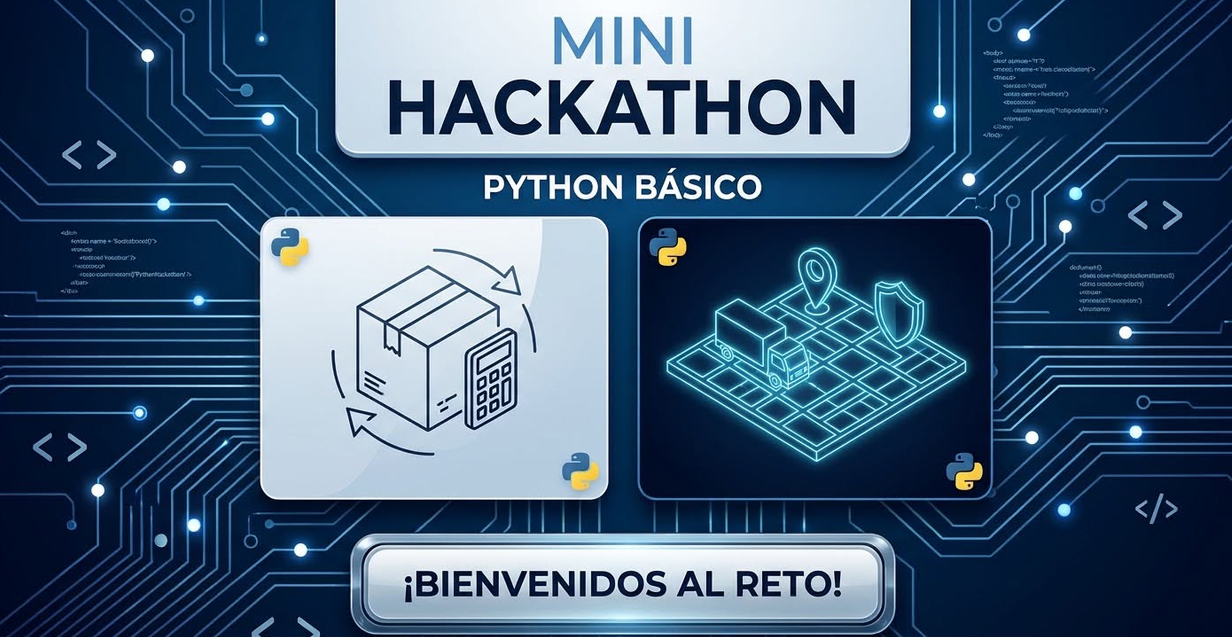